# PRISM Homework 05 — From Pixels to Perception
### Images → K-Means → Color-Vision Simulation → Color Confusion

**Project:** PRISM — *Perceptual Recoloring for Inclusive School Materials*

**Recommended time:** 90–120 minutes

This notebook is deliberately **not fully completed**. You will encounter:

- 🧠 **Predict First** questions — write your prediction before running code.
- ✏️ **TODO** code — replace `None` or `YOUR_CODE_HERE`.
- ✅ **Self-checks** — use them to test your work.
- 🔍 **PRISM Investigator** questions — interpret results rather than only producing them.
- 🚀 **Challenge** tasks — optional extensions if you finish early.

The goal is not to obtain a perfect accessibility system today. The goal is to build the **first working baseline of PRISM** and discover why more advanced image segmentation will eventually be necessary.

---

## Learning objectives

By the end of this homework, you should be able to:

1. Explain how a color image is represented as a numerical array.
2. Interpret RGB pixel values.
3. Reshape an image into a machine-learning dataset.
4. Apply K-means clustering to identify dominant image colors.
5. Compare RGB, HSV, and Lab representations conceptually.
6. Simulate protanopia, deuteranopia, and tritanopia.
7. Use perceptual color distance to identify potentially confusing color pairs.
8. Explain one major weakness of color-only K-means segmentation.

# 0. Setup

Run the following cell first.

We use **Colorspacious** for an established color-vision-deficiency simulation implementation and **scikit-image** for perceptual color-space calculations.

In [ ]:
!pip -q install colorspacious

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw
from sklearn.cluster import KMeans
from skimage import color
from colorspacious import cspace_convert
from itertools import combinations
import ipywidgets as widgets
from IPython.display import display

np.random.seed(42)

print("Setup complete ✓")

Setup complete ✓


## 0.1 Create our practice educational image

To keep the notebook self-contained, we will generate a small textbook-style **ecosystem nutrient-flow diagram**.

Later, you can upload a real textbook figure and repeat the analysis.

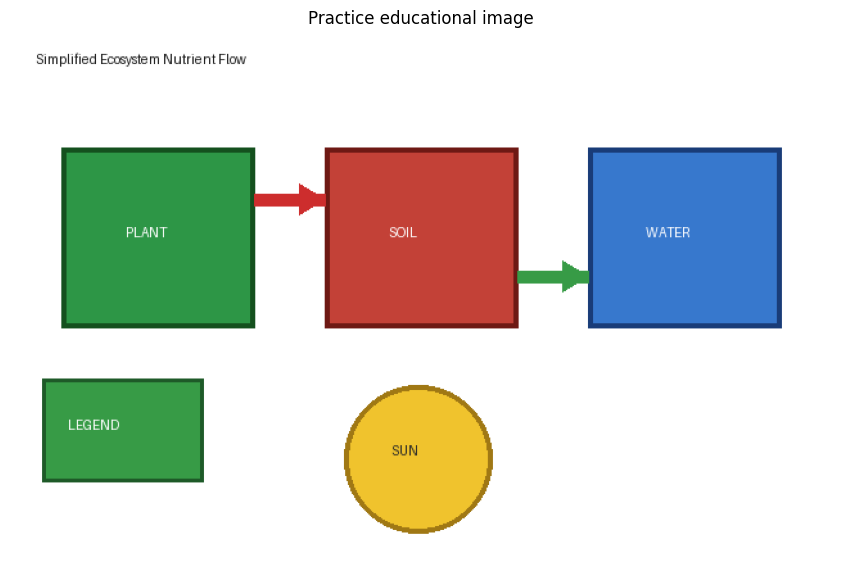

Image shape: (420, 640, 3)


In [ ]:
def make_practice_diagram(width=640, height=420):
    img = Image.new("RGB", (width, height), "white")
    draw = ImageDraw.Draw(img)

    draw.text((20, 15), "Simplified Ecosystem Nutrient Flow", fill=(20, 20, 20))

    draw.rectangle((40, 90, 190, 230), fill=(45, 150, 70), outline=(20, 80, 30), width=4)
    draw.text((90, 150), "PLANT", fill="white")

    draw.rectangle((245, 90, 395, 230), fill=(195, 65, 55), outline=(110, 25, 20), width=4)
    draw.text((295, 150), "SOIL", fill="white")

    draw.rectangle((450, 90, 600, 230), fill=(55, 120, 205), outline=(25, 60, 120), width=4)
    draw.text((495, 150), "WATER", fill="white")

    draw.ellipse((260, 275, 375, 390), fill=(240, 195, 45), outline=(160, 120, 20), width=4)
    draw.text((297, 320), "SUN", fill=(40, 40, 40))

    draw.line((190, 130, 245, 130), fill=(205, 45, 45), width=10)
    draw.polygon([(245,130),(225,118),(225,142)], fill=(205,45,45))

    draw.line((395, 190, 450, 190), fill=(55, 155, 70), width=10)
    draw.polygon([(450,190),(430,178),(430,202)], fill=(55,155,70))

    # Same green family as the plant, but a different semantic role.
    draw.rectangle((25, 270, 150, 350), fill=(55, 155, 70), outline=(30, 90, 40), width=3)
    draw.text((45, 300), "LEGEND", fill="white")

    return np.array(img)

practice_img = make_practice_diagram()

plt.figure(figsize=(11, 7))
plt.imshow(practice_img)
plt.axis("off")
plt.title("Practice educational image")
plt.show()

print("Image shape:", practice_img.shape)

# 1. Images Are Data

A normal RGB image has shape

\[
(H,\;W,\;3)
\]

where:

- \(H\) = height,
- \(W\) = width,
- `3` = red, green, and blue channels.

Each pixel can be represented as:

\[
x=[R,G,B]
\]

---

## 🧠 Predict First — Question 1

Before running the next cell:

The image shape printed above is `(420, 640, 3)`.

1. How many **pixels** are in the image?
2. If each pixel becomes one ML observation, how many **rows** will our dataset contain?
3. How many **features** will each observation contain?

**Your answer:**

> 1.  
> 2.  
> 3.

In [ ]:
coordinates = [
    (120, 100),
    (120, 300),
    (120, 520),
    (330, 320),
]

for y, x in coordinates:
    print(f"Pixel at (x={x}, y={y}): {practice_img[y, x]}")

## ✏️ Exercise 1 — Find the RGB channels

Complete the three lines below.

Remember that an image is indexed as:

```python
image[row, column, channel]
```

and the final dimension contains the RGB channels.

In [ ]:
# TODO: Replace each None with the correct slice.

R_channel = None
G_channel = None
B_channel = None

if R_channel is None or G_channel is None or B_channel is None:
    print("✏️ TODO: extract the three channels first.")
else:
    print("R shape:", R_channel.shape)
    print("G shape:", G_channel.shape)
    print("B shape:", B_channel.shape)

    assert R_channel.shape == practice_img.shape[:2]
    assert G_channel.shape == practice_img.shape[:2]
    assert B_channel.shape == practice_img.shape[:2]
    print("✅ Channel extraction looks correct!")

## 🔍 PRISM Investigator — Question 2

Suppose a pixel is:

\[
[220,\;40,\;30]
\]

Without using a color picker:

- Which channel is strongest?
- What approximate color would you expect?
- Why might a rule such as `R > 150` **not** be enough to identify red pixels reliably?

**Your answer:**

>

# 2. RGB, HSV, and Lab

RGB is convenient because screens use red, green, and blue light. However, RGB is not always the easiest representation for reasoning about human color perception.

| Space | Main idea |
|---|---|
| RGB | How much red, green, blue? |
| HSV | What hue? How saturated? How bright? |
| Lab | Separates lightness from chromatic dimensions and is useful for perceptual comparisons |

For PRISM, the important idea is that a numerical difference in RGB does not necessarily correspond perfectly to a perceived difference between two colors.

## 2.1 Interactive RGB color mixer

Move the sliders and observe how the displayed color changes.

Try these experiments:

1. Set `R=255, G=0, B=0`.
2. Set `R=255, G=255, B=0`.
3. Keep the hue approximately similar but reduce all three values.
4. Create a color that looks gray.

What numerical pattern tends to produce gray?

In [ ]:
def show_rgb_color(R=128, G=128, B=128):
    patch = np.zeros((100, 250, 3), dtype=np.uint8)
    patch[:] = [R, G, B]

    plt.figure(figsize=(5, 2))
    plt.imshow(patch)
    plt.axis("off")
    plt.title(f"RGB = [{R}, {G}, {B}]")
    plt.show()

widgets.interact(
    show_rgb_color,
    R=widgets.IntSlider(min=0, max=255, value=128, step=1),
    G=widgets.IntSlider(min=0, max=255, value=128, step=1),
    B=widgets.IntSlider(min=0, max=255, value=128, step=1),
);

## ✏️ Exercise 2 — Convert one color into HSV and Lab

Complete the variable `sample_rgb`.

Choose **one color from our practice image** by copying an RGB value you observed earlier.

In [ ]:
# TODO: Replace None with an RGB triplet, for example [100, 150, 200].
sample_rgb = None

if sample_rgb is None:
    print("✏️ Choose one RGB color from the practice image.")
else:
    rgb01 = np.array(sample_rgb, dtype=float) / 255.0
    tiny = rgb01.reshape(1, 1, 3)

    hsv = color.rgb2hsv(tiny)[0, 0]
    lab = color.rgb2lab(tiny)[0, 0]

    print("RGB:", sample_rgb)
    print("HSV:", np.round(hsv, 3))
    print("Lab:", np.round(lab, 3))

## 🧠 Question 3

Imagine two colors have different hues but almost identical brightness.

Could they still become difficult to distinguish for a person with CVD?

Explain why PRISM probably should not evaluate **hue alone**.

**Your answer:**

>

# 3. Reuse K-Means for Image Color Recognition

For image color clustering, our observations are **pixels** and our features are:

$$
[R,G,B]
$$

The image starts as:

$$
H\times W\times3
$$

We reshape it into:

$$
(HW)\times3
$$

## ✏️ Exercise 3 — Turn the image into an ML dataset

Complete the reshape operation.

**Target:** `X_pixels` should have exactly 3 columns.

In [ ]:
# TODO: Replace None with one reshape expression.
X_pixels = None

if X_pixels is None:
    print("✏️ TODO: reshape practice_img into an (N, 3) matrix.")
else:
    print("Original image:", practice_img.shape)
    print("ML dataset:", X_pixels.shape)

    assert X_pixels.ndim == 2
    assert X_pixels.shape[1] == 3
    assert X_pixels.shape[0] == practice_img.shape[0] * practice_img.shape[1]
    print("✅ Excellent: each row is now one RGB pixel.")

## 🧠 Predict First — Question 4

If we choose \(K=6\), write six approximate colors you expect K-means to discover.

1.  
2.  
3.  
4.  
5.  
6.  

Which parts of the image might cause unexpected extra clusters?

## ✏️ Exercise 4 — Fit K-Means

Choose a value of \(K\) between 4 and 10.

Complete:

- `K`
- the `KMeans(...)` model
- `fit_predict(...)`

In [ ]:
# TODO 1: Choose K.
K = None

# TODO 2: Create a KMeans model.
kmeans = None

# TODO 3: Fit the model and obtain a label for every pixel.
pixel_labels = None

if K is None or kmeans is None or pixel_labels is None:
    print("✏️ Complete the three TODOs above.")
else:
    palette_rgb = np.clip(kmeans.cluster_centers_, 0, 255).astype(np.uint8)

    print("K =", K)
    print("Number of pixel labels:", len(pixel_labels))
    print("\nCluster centers (dominant RGB colors):")
    print(palette_rgb)

    assert len(pixel_labels) == len(X_pixels)
    assert palette_rgb.shape == (K, 3)
    print("\n✅ K-means completed successfully.")

## Helper — Visualize a palette

In [ ]:
def show_palette(palette, title="Dominant palette"):
    palette = np.asarray(palette, dtype=np.uint8)
    strip = np.zeros((80, 100 * len(palette), 3), dtype=np.uint8)

    for i, c in enumerate(palette):
        strip[:, i*100:(i+1)*100] = c

    plt.figure(figsize=(max(6, len(palette) * 1.4), 2))
    plt.imshow(strip)
    plt.xticks(
        np.arange(len(palette)) * 100 + 50,
        [f"C{i}" for i in range(len(palette))]
    )
    plt.yticks([])
    plt.title(title)
    plt.show()

if 'palette_rgb' in globals():
    show_palette(palette_rgb)

## ✏️ Exercise 5 — Reconstruct the image using only K colors

Replace each original pixel with the RGB centroid belonging to its cluster.

In [ ]:
if 'palette_rgb' not in globals():
    print("Complete Exercise 4 first.")
else:
    # TODO: Use pixel_labels to select the corresponding palette color.
    compressed_pixels = None

    if compressed_pixels is None:
        print("✏️ TODO: reconstruct each pixel using its cluster centroid.")
    else:
        compressed_img = compressed_pixels.reshape(practice_img.shape).astype(np.uint8)

        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        axes[0].imshow(practice_img)
        axes[0].set_title("Original")
        axes[0].axis("off")

        axes[1].imshow(compressed_img)
        axes[1].set_title(f"K-means reconstruction, K={K}")
        axes[1].axis("off")
        plt.show()

## 🔍 PRISM Investigator — Question 5

1. Which details did K-means preserve?
2. Which details did it damage or simplify?
3. Did every cluster correspond to exactly one meaningful object?
4. If two completely different objects use the same green color, can K-means tell them apart?

**Your answer:**

>

# 4. Color-Vision-Deficiency Simulation

We examine:

- **Protanopia**
- **Deuteranopia**
- **Tritanopia**

In the Colorspacious API, severity `100` represents the maximum simulated deficiency for the corresponding protan/deutan/tritan model.

These are computational approximations, not exact representations of every individual's subjective experience.

In [ ]:
def simulate_cvd(rgb_image, cvd_type):
    # rgb_image: uint8 RGB image, values 0..255
    # cvd_type: protanomaly, deuteranomaly, or tritanomaly
    rgb01 = np.asarray(rgb_image, dtype=float) / 255.0

    cvd_space = {
        "name": "sRGB1+CVD",
        "cvd_type": cvd_type,
        "severity": 100
    }

    simulated = cspace_convert(rgb01, cvd_space, "sRGB1")
    simulated = np.clip(simulated, 0, 1)

    return (simulated * 255).astype(np.uint8)

print("CVD simulation helper ready ✓")

## 🧠 Predict First — Question 6

Before viewing the simulations:

- Which part of the practice image do you expect to change most under protanopia/deuteranopia?
- Which color relationships might become more difficult to distinguish?
- Do you expect tritanopia to produce exactly the same problems?

**Your prediction:**

>

In [ ]:
protan_img = simulate_cvd(practice_img, "protanomaly")
deutan_img = simulate_cvd(practice_img, "deuteranomaly")
tritan_img = simulate_cvd(practice_img, "tritanomaly")

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, img, title in zip(
    axes,
    [practice_img, protan_img, deutan_img, tritan_img],
    ["Original", "Protanopia simulation", "Deuteranopia simulation", "Tritanopia simulation"]
):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 🔍 PRISM Investigator — Question 7

1. Which two simulations look most similar?
2. Identify one color pair whose visual separation appears reduced.
3. Did any color remain surprisingly distinguishable?
4. Why is visual inspection alone not enough for a science-fair experiment?

**Your answer:**

>

# 5. Quantifying Color Confusion

We now move from:

> "These colors look similar."

to:

> "These colors became measurably closer under a CVD simulation."

We use **CIEDE2000** color difference:

$$
\Delta E_{00}
$$

A larger value means the two colors are more perceptually separated according to the metric.

We use this as an **experimental color-separation measure**, not a medical diagnostic threshold.

In [ ]:
def rgb_to_lab_single(rgb):
    rgb = np.asarray(rgb, dtype=float) / 255.0
    return color.rgb2lab(rgb.reshape(1, 1, 3))[0, 0]

def delta_e_2000(rgb1, rgb2):
    lab1 = rgb_to_lab_single(rgb1).reshape(1, 1, 3)
    lab2 = rgb_to_lab_single(rgb2).reshape(1, 1, 3)
    return float(color.deltaE_ciede2000(lab1, lab2)[0, 0])

print("Example ΔE00:", round(delta_e_2000([255,0,0], [0,255,0]), 2))

## ✏️ Exercise 6 — Count all unique color pairs

If K-means found \(K\) colors:

$$
\text{pairs}=\frac{K(K-1)}{2}
$$

Complete the code.

In [ ]:
if 'palette_rgb' not in globals():
    print("Complete Exercise 4 first.")
else:
    # TODO
    expected_pairs = None

    actual_pairs = list(combinations(range(K), 2))

    print("Your expected number:", expected_pairs)
    print("Python generated:", len(actual_pairs))

    if expected_pairs is not None:
        assert expected_pairs == len(actual_pairs)
        print("✅ Pair count is correct!")

## Helper — Simulate a palette instead of the whole image

In [ ]:
def simulate_palette(palette, cvd_type):
    palette = np.asarray(palette, dtype=np.uint8)
    tiny_image = palette.reshape(1, len(palette), 3)
    simulated = simulate_cvd(tiny_image, cvd_type)
    return simulated.reshape(len(palette), 3)

if 'palette_rgb' in globals():
    palettes = {
        "Normal": palette_rgb,
        "Protanopia": simulate_palette(palette_rgb, "protanomaly"),
        "Deuteranopia": simulate_palette(palette_rgb, "deuteranomaly"),
        "Tritanopia": simulate_palette(palette_rgb, "tritanomaly"),
    }

    for name, pal in palettes.items():
        show_palette(pal, title=name)

## ✏️ Exercise 7 — Build the pairwise distance table

For every pair of cluster colors, calculate normal, protanopia, deuteranopia, and tritanopia \(\Delta E_{00}\).

**Hint:** use `delta_e_2000(color1, color2)`.

In [ ]:
if 'palette_rgb' not in globals():
    print("Complete Exercise 4 first.")
else:
    normal_pal = palettes["Normal"]
    protan_pal = palettes["Protanopia"]
    deutan_pal = palettes["Deuteranopia"]
    tritan_pal = palettes["Tritanopia"]

    rows = []

    for i, j in combinations(range(K), 2):

        # TODO: Replace each None.
        normal_d = None
        protan_d = None
        deutan_d = None
        tritan_d = None

        if None in [normal_d, protan_d, deutan_d, tritan_d]:
            continue

        rows.append({
            "pair": f"C{i}–C{j}",
            "i": i,
            "j": j,
            "normal_dE": normal_d,
            "protan_dE": protan_d,
            "deutan_dE": deutan_d,
            "tritan_dE": tritan_d,
        })

    if len(rows) == 0:
        print("✏️ TODO: complete the four distance calculations inside the loop.")
    else:
        distance_df = pd.DataFrame(rows)
        display(distance_df.round(2))

        assert len(distance_df) == K * (K - 1) // 2
        print("✅ Complete pairwise distance table created.")

# 6. Which Color Pair Loses the Most Separation?

Define a simple **separation retention ratio**:

$$
R_{ij}^{(k)}
=
\frac{d_{ij}^{(k)}}{d_{ij}^{normal}}
$$

If the original distance is 50 and the simulated distance is 10:

$$
R=0.20
$$

The colors retain approximately 20% of their original measured separation.

This is a teaching/research metric for exploration, not a validated clinical score.

## ✏️ Exercise 8 — Calculate retention ratios

In [ ]:
if 'distance_df' not in globals():
    print("Complete Exercise 7 first.")
else:
    results = distance_df.copy()

    # TODO
    results["protan_ratio"] = None
    results["deutan_ratio"] = None
    results["tritan_ratio"] = None

    if results[["protan_ratio","deutan_ratio","tritan_ratio"]].isna().all().all():
        print("✏️ TODO: calculate the three retention ratios.")
    else:
        display(
            results[
                ["pair", "normal_dE", "protan_dE", "deutan_dE", "tritan_dE",
                 "protan_ratio", "deutan_ratio", "tritan_ratio"]
            ].round(3)
        )

## ✏️ Exercise 9 — Find the most affected pair

Use `.idxmin()` on each retention-ratio column.

In [ ]:
if 'results' not in globals():
    print("Complete Exercise 8 first.")
else:
    # TODO
    worst_protan_idx = None
    worst_deutan_idx = None
    worst_tritan_idx = None

    if None in [worst_protan_idx, worst_deutan_idx, worst_tritan_idx]:
        print("✏️ TODO: use idxmin() to find the minimum ratio row.")
    else:
        print("Most affected under protanopia:")
        display(results.loc[[worst_protan_idx]].round(3))

        print("Most affected under deuteranopia:")
        display(results.loc[[worst_deutan_idx]].round(3))

        print("Most affected under tritanopia:")
        display(results.loc[[worst_tritan_idx]].round(3))

## 🔍 PRISM Investigator — Question 8

1. Which cluster pair loses the most separation under protanopia?
2. Which pair loses the most under deuteranopia?
3. Which pair loses the most under tritanopia?
4. Are the answers identical?
5. What actual colors do those cluster IDs represent?

**Your answer:**

>

# 7. Mini PRISM Recoloring Challenge

We now attempt a primitive recoloring.

PRISM can replace one problematic cluster with candidate colors and measure whether the worst-case color separation improves.

In [ ]:
candidate_colors = {
    "dark_blue": np.array([25, 80, 180]),
    "orange": np.array([230, 125, 30]),
    "purple": np.array([135, 70, 180]),
    "cyan": np.array([35, 180, 190]),
    "dark_gray": np.array([55, 55, 55]),
    "magenta": np.array([200, 55, 150]),
}

show_palette(
    np.array(list(candidate_colors.values())),
    title="Candidate replacement colors"
)
print(list(candidate_colors.keys()))

## ✏️ Exercise 10 — Choose a target cluster manually

Inspect the deuteranopia results and choose one cluster ID to recolor.

**Why this cluster?**

>

Then set `target_cluster`.

In [ ]:
# TODO: choose an integer from 0 to K-1.
target_cluster = None

if target_cluster is None:
    print("✏️ Choose a cluster to recolor.")
else:
    assert 0 <= target_cluster < K
    print("Original cluster color:", palette_rgb[target_cluster])

## ✏️ Exercise 11 — Test every replacement candidate

For each candidate:

1. copy the palette,
2. replace `target_cluster`,
3. simulate deuteranopia,
4. calculate the minimum pairwise $\Delta E_{00}$.

Complete the missing assignment inside the loop.

In [ ]:
def minimum_pairwise_distance(palette):
    distances = []
    for i, j in combinations(range(len(palette)), 2):
        distances.append(delta_e_2000(palette[i], palette[j]))
    return min(distances)

if target_cluster is None:
    print("Complete Exercise 10 first.")
else:
    candidate_rows = []

    for name, new_color in candidate_colors.items():
        test_palette = palette_rgb.copy()

        # TODO: Replace the chosen cluster with new_color.
        # Example structure:
        # test_palette[ ... ] = ...

        simulated_test = simulate_palette(test_palette, "deuteranomaly")
        min_d = minimum_pairwise_distance(simulated_test)

        change_cost = delta_e_2000(
            palette_rgb[target_cluster],
            new_color
        )

        candidate_rows.append({
            "candidate": name,
            "minimum_deutan_dE": min_d,
            "change_cost_dE": change_cost
        })

    candidate_df = pd.DataFrame(candidate_rows)
    display(candidate_df.sort_values("minimum_deutan_dE", ascending=False).round(2))

## 🧠 Question 9 — Accessibility versus preservation

Suppose:

- **Solution A** gives a very large accessibility improvement but drastically changes the image.
- **Solution B** gives a moderate improvement with a much smaller visual change.

Which would you prefer, and why?

**Your answer:**

>

This motivates a future PRISM objective:

$$
J=
\text{confusion risk}
+
\lambda(\text{visual change})
$$

# 8. The Critical Failure of PRISM v0.1

The **PLANT** region and the **LEGEND** box intentionally use nearly the same green.

K-means may assign them to the same cluster.

But they have different meanings.

---

## 🔍 PRISM Investigator — Question 10

Suppose PRISM decides this green cluster should become purple.

1. What happens to both the plant and legend box?
2. Is that always desirable?
3. What information is K-means missing?

**Your answer:**

>

## Complete the key sentence

> **K-means understands ____________________, but it does not understand ____________________.**

Think about:

- similar pixels,
- separate regions,
- objects,
- labels,
- semantic meaning.

**Your answer:**

>

# 9. 🚀 Optional Challenge — Add Pixel Location to K-Means

Currently:

$$
x_i=[R,G,B]
$$

Try:

$$
x_i=[R,G,B,\alpha X,\alpha Y]
$$

Then identical green pixels far apart may become easier to separate.

This is still **not semantic segmentation**, but it introduces spatial context.

In [ ]:
H, W, _ = practice_img.shape
yy, xx = np.indices((H, W))

# TODO:
# 1. Flatten RGB to (N, 3)
# 2. Normalize xx and yy to approximately 0..255
# 3. Multiply positions by alpha
# 4. Concatenate RGB + x + y into (N, 5)

alpha = 0.5
X_rgbxy = None

if X_rgbxy is None:
    print("🚀 Optional: construct the 5-feature RGBXY dataset.")
else:
    print("RGBXY feature matrix:", X_rgbxy.shape)
    assert X_rgbxy.shape == (H * W, 5)
    print("✅ You just added spatial context to clustering!")

## 🔍 Challenge Reflection

If RGBXY clustering performs better than RGB clustering, what does that tell us?

If it still cannot understand that a region is a "plant", "arrow", or "legend", what technology might we need later?

**Your answer:**

>

# 10. Optional — Test a Real Educational Image

Upload a screenshot or image from:

- a chart,
- a map,
- a biology diagram,
- a chemistry illustration,
- an infographic.

For your first experiment, avoid a complex photograph.

In [ ]:
try:
    from google.colab import files

    uploaded = files.upload()

    if uploaded:
        filename = next(iter(uploaded))
        uploaded_img = np.array(Image.open(filename).convert("RGB"))

        plt.figure(figsize=(10, 6))
        plt.imshow(uploaded_img)
        plt.axis("off")
        plt.title(filename)
        plt.show()

        print("Uploaded image shape:", uploaded_img.shape)
except ImportError:
    print("This upload helper is designed for Google Colab.")

## Real-image investigation

If you uploaded an image, repeat:

1. reshape into `(N, 3)`,
2. K-means,
3. dominant palette,
4. P/D/T simulation,
5. pairwise color-distance analysis.

Then answer:

> Did PRISM v0.1 behave better or worse on a real educational image than on the synthetic diagram? Why?

**Your answer:**

>

# 11. Final Homework Questions

### Q1
Why can an RGB image be treated as a machine-learning dataset?

>

### Q2
What does one K-means centroid mean in PRISM?

>

### Q3
Why does increasing \(K\) preserve more image detail but also make the accessibility problem harder?

>

### Q4
Why should PRISM compare colors **after** CVD simulation?

>

### Q5
Why is CIEDE2000 more appropriate than simple Euclidean RGB distance for this project?

>

### Q6
Why can the smallest pairwise color distance matter?

>

### Q7
What is the difference between **color clustering** and **semantic understanding**?

>

### Q8
What problem might SAM or semantic segmentation solve for PRISM?

>

### Q9
Why should PRISM minimize both color confusion and unnecessary recoloring?

>

### Q10 — Design the next experiment

Write:

- **Research question**
- **Independent variable**
- **Dependent variable**
- **Hypothesis**

>

# 12. Submission Checklist

- [ ] RGB channels extracted
- [ ] One color converted to HSV and Lab
- [ ] Image reshaped into ML data
- [ ] K-means applied
- [ ] Dominant palette displayed
- [ ] K-color image reconstructed
- [ ] Three CVD simulations viewed
- [ ] Pairwise color-distance table created
- [ ] Separation-retention ratios calculated
- [ ] Most affected pairs identified
- [ ] Baseline recoloring attempted
- [ ] Investigator questions answered
- [ ] K-means limitation explained

---

## What comes next?

You have built:

$$
\boxed{\text{PRISM v0.1}}
$$

The system understands **colors**.

The next research question is:

> **How can PRISM understand regions and objects?**

That question will motivate masks, connected components, spatial segmentation, and eventually **SAM**.